# Demo -- pipeline completo (imagem → YOLO → classificador → cariótipo)

Reproduz o fluxo de ponta a ponta que o `cytoml-demo` vai expor depois (Fase 6), usando só os artefatos já treinados nesta máquina:

1. **Imagem** de uma metáfase (nunca vista em treino/validação de nenhum dos dois modelos).
2. **Detector (YOLO26m)** localiza cada cromossomo -- ele não sabe de qual tipo é, só "aqui tem um cromossomo".
3. **Classificador** decide o tipo (A1...Y) de cada recorte que o detector encontrou.
4. **Montagem do cariótipo** -- organiza tudo no formato clássico (pares 1-22, X, Y).

A anotação original (XML) só é usada no final, pra conferir a acurácia -- em produção (sem XML disponível) as etapas 1-4 rodam exatamente igual.

In [1]:
import sys
from collections import defaultdict
from pathlib import Path

REPO_ROOT = Path("../../..").resolve()
sys.path.insert(0, str(REPO_ROOT / "src" / "classification"))
sys.path.insert(0, str(REPO_ROOT / "src" / "preprocessing"))

import cv2
import numpy as np
import torch
import torch.nn.functional as functional
import matplotlib.pyplot as plt
from ultralytics import YOLO

from crops import letterbox
from dataset import IMAGENET_MEAN, IMAGENET_STD
from evaluate import load_checkpoint
from voc_to_yolo import DENVER_CLASSES, parse_annotation

YOLO_CHECKPOINT = REPO_ROOT / "models" / "yolo" / "yolo26m" / "runs" / "baseline" / "best.pt"
CLASSIFIER_CHECKPOINT = Path("../runs/resnet50-30epochs/best.pt")  # ajustar pro seu checkpoint

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
detector = YOLO(str(YOLO_CHECKPOINT))
classifier = load_checkpoint(CLASSIFIER_CHECKPOINT, device)
print(f"Detector: {YOLO_CHECKPOINT.name}")
print(f"Classificador carregado em {device}: {CLASSIFIER_CHECKPOINT}")

Detector: best.pt
Classificador carregado em cuda: ../runs/resnet50-30epochs/best.pt


## Passo 1 -- escolher a imagem

`1060391` é uma das 694 imagens do split de teste com exatamente **46 cromossomos** anotados -- um cariótipo humano completo (23 pares), o cenário mais direto pra avaliar o pipeline. Já vem com o pré-processamento da Fase 1 aplicado (mediana + CLAHE), que é o que os dois modelos esperam como entrada. Pra testar outra imagem com 46 cromossomos, troca `IMAGE_NAME` por qualquer uma da lista impressa abaixo.

In [2]:
test_dir = REPO_ROOT / "data" / "processed" / "24_chromosomes_object" / "images" / "test"
raw_annotations_dir = REPO_ROOT / "data" / "raw" / "24_chromosomes_object" / "annotations"

images_with_46 = sorted(
    img.stem
    for img in test_dir.glob("*.jpg")
    if len(parse_annotation(raw_annotations_dir / f"{img.stem}.xml")["objects"]) == 46
)
print(f"{len(images_with_46)} imagens de teste com exatamente 46 cromossomos anotados")

IMAGE_NAME = "1060391"

image_path = test_dir / f"{IMAGE_NAME}.jpg"
annotation_path = raw_annotations_dir / f"{IMAGE_NAME}.xml"

image_bgr = cv2.imread(str(image_path))
annotation = parse_annotation(annotation_path)  # só pra conferir acurácia no final
print(f"Imagem: {image_path.name}  ({image_bgr.shape[1]}x{image_bgr.shape[0]}px)")
print(f"Cromossomos anotados (ground truth): {len(annotation['objects'])}")

694 imagens de teste com exatamente 46 cromossomos anotados
Imagem: 1060391.jpg  (759x619px)
Cromossomos anotados (ground truth): 46


## Passo 2 -- detecção (YOLO)

O detector não usa a anotação em nenhum momento -- só a imagem. Cada caixa é um cromossomo que ele encontrou sozinho.

Cromossomos detectados: 46


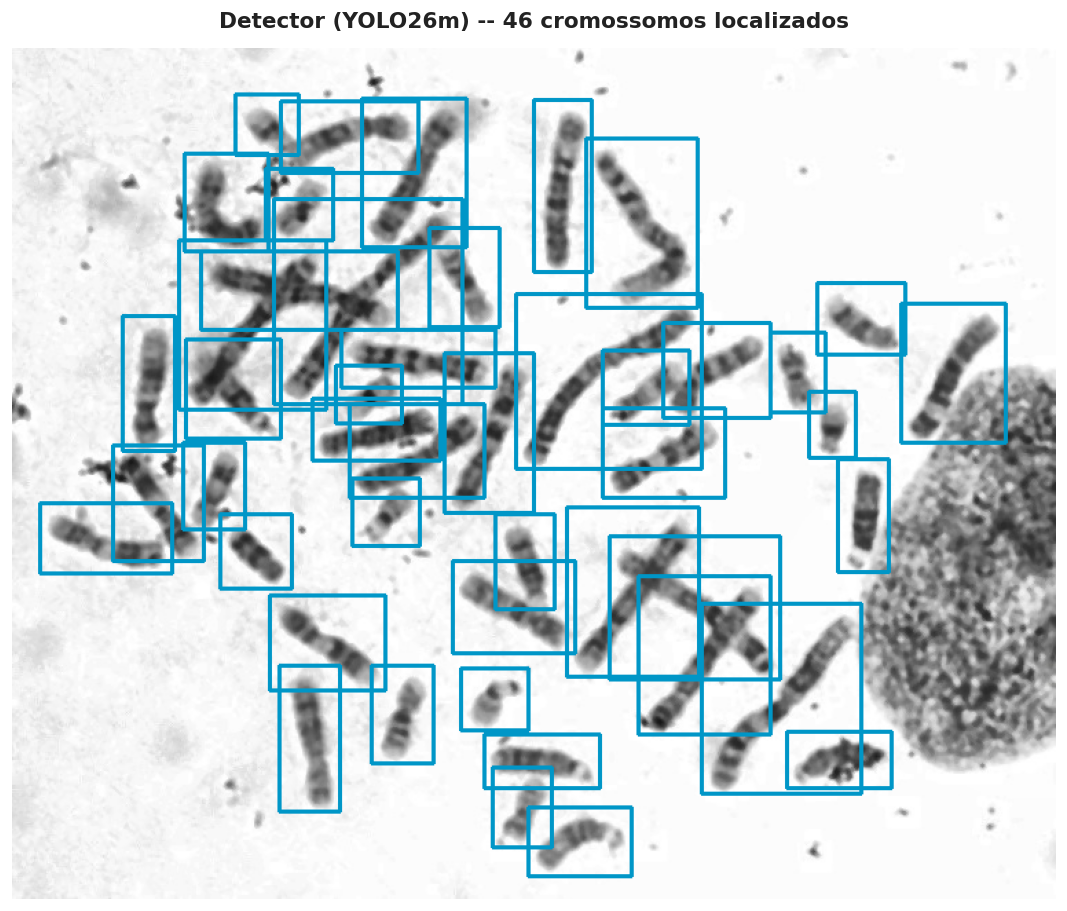

In [3]:
results = detector.predict(str(image_path), verbose=False)[0]
det_boxes = results.boxes.xyxy.cpu().numpy()
det_conf = results.boxes.conf.cpu().numpy()
print(f"Cromossomos detectados: {len(det_boxes)}")

vis = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB).copy()
for (x1, y1, x2, y2) in det_boxes.astype(int):
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 150, 199), 2)

fig, ax = plt.subplots(figsize=(9, 8), dpi=120, facecolor="white")
ax.imshow(vis)
ax.set_title(
    f"Detector (YOLO26m) -- {len(det_boxes)} cromossomos localizados",
    fontsize=13, fontweight="bold", color="#222", pad=12,
)
ax.axis("off")
plt.tight_layout()
plt.show()

## Passo 3 -- classificação de cada recorte

Cada caixa que o detector encontrou vira um recorte independente, que passa pelo classificador (mesmo pré-processamento do treino: escala de cinza + letterbox 224x224).

Pra conferir a acurácia no final, cada detecção é casada (por IoU) com a anotação verdadeira mais próxima -- isso é só pra gerar o relatório, o modelo em si nunca vê a anotação.

In [4]:
def iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


@torch.no_grad()
def predict_crop(image_gray: np.ndarray) -> np.ndarray:
    canvas = letterbox(image_gray, size=224)
    rgb = np.stack([canvas] * 3, axis=-1).astype(np.float32) / 255.0
    rgb = (rgb - IMAGENET_MEAN) / IMAGENET_STD
    tensor = torch.from_numpy(rgb.transpose(2, 0, 1)).float().unsqueeze(0).to(device)
    logits = classifier(tensor)
    return functional.softmax(logits, dim=1).cpu().numpy()[0]


gt_boxes = [
    (obj["xmin"], obj["ymin"], obj["xmax"], obj["ymax"]) for obj in annotation["objects"]
]
gt_names = [obj["name"] for obj in annotation["objects"]]

# casamento guloso detecção <-> anotação, só para o relatório de acurácia
pairs = sorted(
    (
        (iou_xyxy(det_boxes[di], gt_boxes[gi]), di, gi)
        for di in range(len(det_boxes))
        for gi in range(len(gt_boxes))
    ),
    reverse=True,
)
matched_gt_for_det, used_gt = {}, set()
for score, di, gi in pairs:
    if score < 0.3 or di in matched_gt_for_det or gi in used_gt:
        continue
    matched_gt_for_det[di] = gi
    used_gt.add(gi)

height, width = image_bgr.shape[:2]
entries = []
for di, (x1, y1, x2, y2) in enumerate(det_boxes):
    x1, y1 = max(0, int(x1)), max(0, int(y1))
    x2, y2 = min(width, int(x2)), min(height, int(y2))
    crop = cv2.cvtColor(image_bgr[y1:y2, x1:x2], cv2.COLOR_BGR2GRAY)
    probs = predict_crop(crop)
    pred_name = DENVER_CLASSES[int(probs.argmax())]
    true_name = gt_names[matched_gt_for_det[di]] if di in matched_gt_for_det else None
    entries.append(
        {"image": crop, "pred": pred_name, "true": true_name, "conf": float(probs.max())}
    )

missed = len(gt_boxes) - len(used_gt)
print(f"Classificados: {len(entries)}")
print(f"Anotações sem detecção correspondente (falso negativo do detector): {missed}")

Classificados: 46
Anotações sem detecção correspondente (falso negativo do detector): 0


## Passo 4 -- montagem do cariótipo

Organiza tudo pela classe **prevista** pelo classificador (é isso que um usuário final veria, sem nenhuma anotação de apoio), no layout clássico: seções por grupo de Denver (A-G, Sexuais), colunas numeradas 1-22/X/Y. A borda de cada cromossomo indica o resultado da conferência contra a anotação verdadeira.

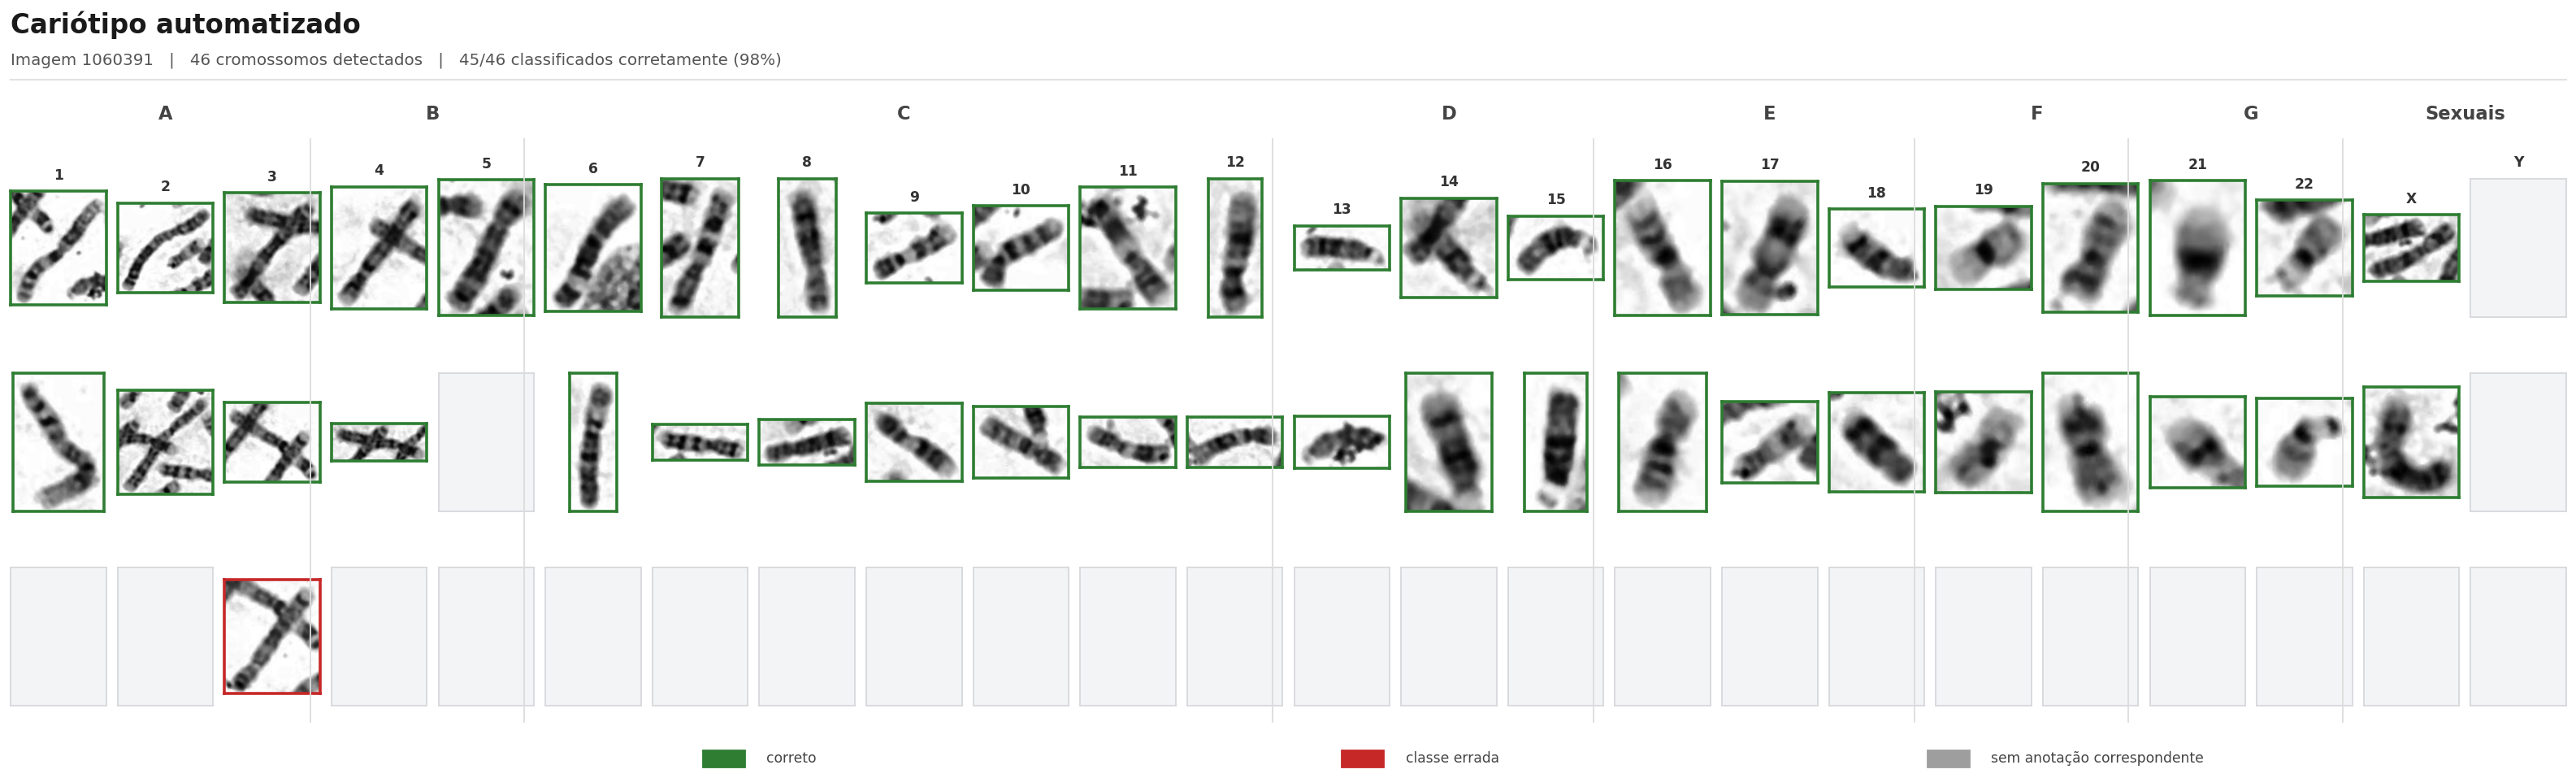

In [5]:
COLOR_CORRECT = "#2e7d32"
COLOR_WRONG = "#c62828"
COLOR_UNKNOWN = "#9e9e9e"
CARD_BG = "#f3f4f6"
CARD_EDGE = "#d7d8dc"


def pair_label(class_name: str) -> str:
    """'A1' -> '1', 'C12' -> '12', 'X' -> 'X'."""
    return class_name if class_name in ("X", "Y") else class_name[1:]


# seções contíguas por letra do grupo de Denver (X/Y viram uma seção só, "Sexuais")
sections, current_letter, start = [], None, 0
for i, name in enumerate(DENVER_CLASSES):
    letter = name[0]
    if letter != current_letter:
        if current_letter is not None:
            sections.append((current_letter, start, i))
        current_letter, start = letter, i
sections.append((current_letter, start, len(DENVER_CLASSES)))
if len(sections) >= 2 and sections[-1][0] == "Y" and sections[-2][0] == "X":
    (_, xs, _), (_, _, ye) = sections[-2], sections[-1]
    sections = sections[:-2] + [("Sexuais", xs, ye)]

groups = defaultdict(list)
for e in entries:
    groups[e["pred"]].append(e)

n_cols = len(DENVER_CLASSES)
n_rows = max((len(groups.get(c, [])) for c in DENVER_CLASSES), default=1) or 1

fig = plt.figure(figsize=(n_cols * 1.05, n_rows * 1.95 + 1.6), dpi=130, facecolor="white")
gs = fig.add_gridspec(
    n_rows, n_cols, wspace=0.12, hspace=0.4,
    left=0.02, right=0.98, top=0.78, bottom=0.11,
)
axes = np.empty((n_rows, n_cols), dtype=object)
for r in range(n_rows):
    for c in range(n_cols):
        axes[r, c] = fig.add_subplot(gs[r, c])

for col, class_name in enumerate(DENVER_CLASSES):
    entries_col = groups.get(class_name, [])
    for row_i in range(n_rows):
        ax = axes[row_i, col]
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_facecolor(CARD_BG)
        border = CARD_EDGE
        linewidth = 1.0
        if row_i < len(entries_col):
            e = entries_col[row_i]
            ax.imshow(e["image"], cmap="gray", interpolation="bilinear", aspect="equal")
            if e["true"] is None:
                border = COLOR_UNKNOWN
            elif e["pred"] == e["true"]:
                border = COLOR_CORRECT
            else:
                border = COLOR_WRONG
            linewidth = 2.0
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color(border)
            spine.set_linewidth(linewidth)
    axes[0, col].set_title(pair_label(class_name), fontsize=9.5, fontweight="bold", color="#333", pad=8)

fig.canvas.draw()  # finaliza o layout antes de ler a posição dos eixos
for label, c0, c1 in sections:
    x0 = axes[0, c0].get_position().x0
    x1 = axes[0, c1 - 1].get_position().x1
    fig.text((x0 + x1) / 2, 0.855, label, ha="center", fontsize=12.5, fontweight="bold", color="#444")
    if c0 > 0:
        xline = x0 - 0.008
        fig.add_artist(plt.Line2D([xline, xline], [0.09, 0.83], color="#dcdcdc", lw=1, transform=fig.transFigure))

known = [e for e in entries if e["true"] is not None]
correct = sum(e["pred"] == e["true"] for e in known)

fig.text(0.02, 0.965, "Cariótipo automatizado", fontsize=18, fontweight="bold", color="#1a1a1a")
fig.text(
    0.02, 0.925,
    f"Imagem {IMAGE_NAME}   |   {len(det_boxes)} cromossomos detectados   |   "
    f"{correct}/{len(known)} classificados corretamente ({correct / len(known):.0%})",
    fontsize=11, color="#555",
)
fig.add_artist(plt.Line2D([0.02, 0.98], [0.905, 0.905], color="#e3e3e3", lw=1.2, transform=fig.transFigure))

legend_items = [
    ("correto", COLOR_CORRECT),
    ("classe errada", COLOR_WRONG),
    ("sem anotação correspondente", COLOR_UNKNOWN),
]
legend_x = [0.28, 0.52, 0.74]
for (text, color), x in zip(legend_items, legend_x, strict=True):
    fig.add_artist(plt.Rectangle((x, 0.032), 0.016, 0.022, transform=fig.transFigure, color=color))
    fig.text(x + 0.024, 0.043, text, fontsize=9.5, color="#444", va="center")

plt.show()

## Resumo em texto

In [6]:
print(f"Cromossomos anotados na imagem: {len(gt_boxes)}")
print(f"Detectados pelo YOLO: {len(det_boxes)}")
print(f"Não detectados (falso negativo do detector): {missed}")
print(f"Classificados corretamente: {correct}/{len(known)} ({correct / len(known):.1%})")

wrong = [e for e in known if e["pred"] != e["true"]]
if wrong:
    print("\nErros de classificação:")
    for e in wrong:
        print(f"  - {e['true']} confundido com {e['pred']} (confiança: {e['conf']:.0%})")

Cromossomos anotados na imagem: 46
Detectados pelo YOLO: 46
Não detectados (falso negativo do detector): 0
Classificados corretamente: 45/46 (97.8%)

Erros de classificação:
  - B5 confundido com A3 (confiança: 50%)
